# Week 07: Central limit theorem, confidence interval

**Course:** MATH7810 Python for Data Science (AY2026/27)

Open `W07_Ch4_SamplingShape_Demo.ipynb` first. The instructor runs that demonstration. This notebook is the practice that follows.

Three tasks, in order. Each uses an Input / Process / Output prompt. In Task 1 you write **Input**, **Process**, and **Output**. In Task 2 and Task 3, Input is filled in and you write Process and Output.


## Task 1 — central limit theorem

**Question:** Waiting time in the bank example is exponential with mean 10 minutes. One waiting time is right-skewed, not normal. If we take many samples, when does the histogram of the **sample means** look approximately normal?

Draw **2000** samples of size **5**, and **2000** samples of size **36** (size 36 is the sample size from the lecture example).

Write **Input**, **Process**, and **Output** yourself, then Inline Chat.

**Done when:** two histograms of sample means, each with a normal curve that has mean 10 and standard deviation $10/\sqrt{n}$. The $n = 36$ histogram sits closer to that curve than the $n = 5$ histogram.


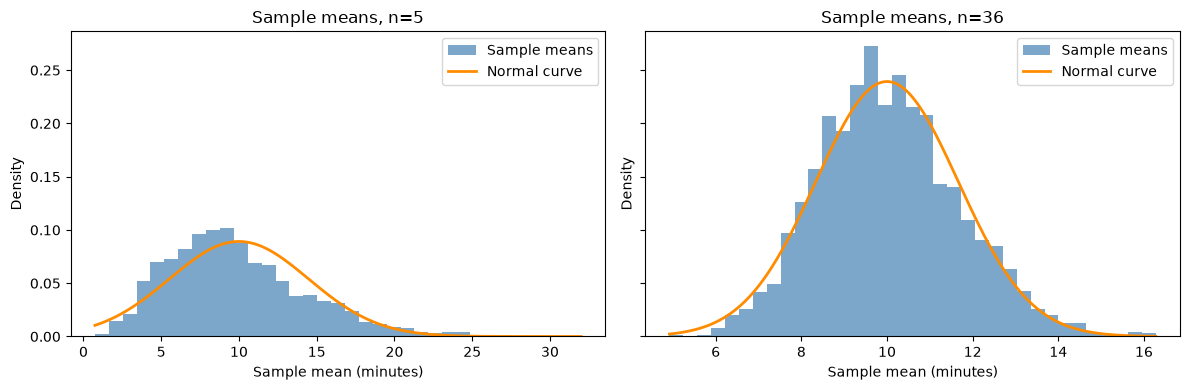

In [1]:
# Task 1 — central limit theorem
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: NumPy, matplotlib.pyplot, and scipy.stats.norm are available. Waiting times follow an Exponential distribution with mean 10 minutes.
#
# Process: Draw 2000 samples of size 5 and 2000 samples of size 36 from the exponential population. Compute each sample mean, then plot side-by-side histograms of the two sets of means with the corresponding Normal curves having mean 10 and standard deviation 10/sqrt(n).
#
# Output: Two density histograms of sample means with Normal curves, clearly labeled for n=5 and n=36.
# --- End prompt ---
# Fill Input, Process and Output from the task. 
# Inline Chat (Cmd+I / Ctrl+I): implement the prompt in the comments. Keep.
#
# --- generated / your code below ---
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)
n_rep = 2000
population_mean = 10
sample_sizes = [5, 36]
sample_means = {}

for n in sample_sizes:
    draws = rng.exponential(scale=population_mean, size=(n_rep, n))
    sample_means[n] = draws.mean(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, n in zip(axes, sample_sizes):
    means = sample_means[n]
    sd_mean = population_mean / np.sqrt(n)
    x_grid = np.linspace(means.min(), means.max(), 400)
    ax.hist(means, bins=35, density=True, alpha=0.7, color="steelblue", label="Sample means")
    ax.plot(x_grid, stats.norm.pdf(x_grid, loc=population_mean, scale=sd_mean),
            color="darkorange", linewidth=2, label="Normal curve")
    ax.set_title(f"Sample means, n={n}")
    ax.set_xlabel("Sample mean (minutes)")
    ax.set_ylabel("Density")
    ax.legend()
fig.tight_layout()
plt.show()


**Check:** The population of waiting times is still exponential. Which histogram of **sample means** is closer to a normal curve, and why? Type in the next cell, then **run** it.


In [2]:
# Task 1 — write BETWEEN the triple quotes, then RUN
task1_note = """
The histogram for n=36 is closer to a Normal curve than the histogram for n=5. The larger sample size gives the Central Limit Theorem more effect, so the sample means are approximately normal even though individual waiting times are exponential.
"""
print(task1_note)



The histogram for n=36 is closer to a Normal curve than the histogram for n=5. The larger sample size gives the Central Limit Theorem more effect, so the sample means are approximately normal even though individual waiting times are exponential.



## Task 2 — confidence interval for the population mean, population $\sigma$ unknown

Run the setup cell first. It loads `checkout_lab.csv`.

`purchased` is 1 or 0. `order_value` is missing when `purchased` is 0.

**Question:** Among visits **with a purchase**, what is a **95% confidence interval for the population mean** order value?

The population standard deviation of order value is not known. Use a $t$ interval.

**Done when:** the cell prints the sample size, the sample mean, and the two endpoints.


In [3]:
# Setup for Task 2 and Task 3. 
import numpy as np
from scipy import stats
import pandas as pd

# checkout_lab.csv is in the week07 folder, next to this notebook.
# One row is one visit. Task 2 and Task 3 use this table.
visits = pd.read_csv("checkout_lab.csv")

# shape is (number of rows, number of columns). head() prints the first five rows.
print("rows, columns:", visits.shape)
print(visits.head())


rows, columns: (500, 6)
  checkout_page  order_value  purchased gender browser  time_on_page
0             B        24.97          1      F  chrome         36.30
1             C        39.32          1      F  chrome         51.13
2             C        38.03          1      M  safari         48.56
3             C        25.87          1      M  chrome         24.23
4             B        20.41          1      F  safari         30.21


In [4]:
# Task 2 — confidence interval for the population mean
# --- Write your AI prompt here (Input → Process → Output) ---
# Input: dataframe visits is already loaded and contains order_value and purchased.
#
# Process: Keep only visits with purchased == 1, remove missing order_value values, and use a 95% t interval because the population standard deviation is unknown. Calculate and print n, the sample mean, and the lower and upper confidence limits.
#
# Output: The sample size, sample mean, and endpoints of the 95% confidence interval for the population mean order value among purchasers.
# --- End prompt ---
# Fill Process and Output from the task. Highlight this comment block.
# Inline Chat (Cmd+I / Ctrl+I): implement the prompt in the comments. Keep.
#
# --- generated / your code below ---
purchase_values = visits.loc[visits["purchased"].eq(1), "order_value"].dropna()
n_purchase = purchase_values.size
mean_purchase = purchase_values.mean()
se_purchase = stats.sem(purchase_values)
ci_mean = stats.t.interval(
    confidence=0.95,
    df=n_purchase - 1,
    loc=mean_purchase,
    scale=se_purchase,
)
print(f"n: {n_purchase}")
print(f"Sample mean: {mean_purchase:.4f}")
print(f"95% t interval: ({ci_mean[0]:.4f}, {ci_mean[1]:.4f})")


n: 423
Sample mean: 30.2393
95% t interval: (29.5508, 30.9279)


If we repeat the same sampling and calculation process 100 times, about 95 of those intervals will contain the true population mean and 5 will not.

## Task 3 — confidence interval for the population proportion

Use the same `visits` table from the setup cell.

**Question:** Among **all visits in this file**, what is a **95% confidence interval for the population proportion** who purchased?

Use a $z$ interval.

**Done when:** the cell prints the sample size, the sample proportion, and the two endpoints.


In [5]:
# Task 3 — confidence interval for the population proportion
# --- IPO prompt ---
# Input: dataframe visits is already loaded and purchased is coded as 1 or 0.
# Process: Calculate the sample size and sample proportion who purchased, then use a 95% z interval with standard error sqrt(p_hat * (1-p_hat) / n).
# Output: Print the sample size, sample proportion, and lower and upper endpoints of the 95% z interval.
# --- End prompt ---

n_visits = visits["purchased"].size
p_hat = visits["purchased"].mean()
z_star = stats.norm.ppf(0.975)
se_proportion = np.sqrt(p_hat * (1 - p_hat) / n_visits)
ci_proportion = (p_hat - z_star * se_proportion, p_hat + z_star * se_proportion)
print(f"n: {n_visits}")
print(f"Sample proportion: {p_hat:.4f}")
print(f"95% z interval: ({ci_proportion[0]:.4f}, {ci_proportion[1]:.4f})")


n: 500
Sample proportion: 0.8460
95% z interval: (0.8144, 0.8776)
